# Лабораторная работа № 4
**Тема:** Стационарность и корреляционный анализ временных рядов

**Цель:** проверить стационарность временного ряда и подобрать преобразования и порядок дифференцирования $d$ и сезонного дифференцирования $D$

**Задачи:**
1. Использовать собственный генератор из лабораторной № 1
2. Исследовать ряд с трендом и сезонностью: графики, ACF и PACF
3. Провести тесты ADF, PP, KPSS, DF-GLS
4. Сравнить исходные данные, первые разности и сезонные разности
5. Сопоставить ручной подбор $d,D$ с ndiffs() и nsdiffs()
6. Обосновать итоговое преобразование и сформулировать выводы

*Важно:* дата начала берётся из генератора (00:00 текущего дня), а все вычисления воспроизводимы благодаря фиксированному `seed`. При повторном запуске в другой день изменятся календарные подписи, но не числовые значения ряда.

## 1. Библиотеки и оформление
Для работы нужны `numpy`, `pandas`, `matplotlib`, `statsmodels`, `scipy`, `pmdarima` и `arch`

In [2]:
%pip install -q pmdarima arch

In [3]:
from datetime import datetime, timedelta
from pathlib import Path
import sys
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import dates as mdates
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pmdarima.arima import ndiffs, nsdiffs

# Пытаемся подключить точные реализации PP и DF-GLS.
try:
    from arch.unitroot import PhillipsPerron, DFGLS
    ARCH_AVAILABLE = True
except ImportError:
    try:
        print("Устанавливаем библиотеку arch (PP и DF-GLS)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "arch", "-q"])
        from arch.unitroot import PhillipsPerron, DFGLS
        ARCH_AVAILABLE = True
    except (ImportError, subprocess.CalledProcessError):
        ARCH_AVAILABLE = False
        print("arch не установлена. PP и DF-GLS будут пропущены; установите arch и повторите запуск.")

PURPLE = "#7C3AED"
DARK = "#5B21B6"
LILAC = "#A78BFA"
LIGHT = "#DDD6FE"
PINK = "#C084FC"
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})

OUTPUT_DIR = Path(".")
IMAGE_DIR = OUTPUT_DIR / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

def save_image(name):
    plt.tight_layout()
    plt.savefig(IMAGE_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

print("Библиотека arch доступна:", ARCH_AVAILABLE)

Библиотека arch доступна: True


## 2. Генератор из первой лабораторной
Ниже приведена исходная функция `generate_time_series()` **без изменения алгоритма**: шаг 5 минут, базовый уровень 100, настраиваемые тренд, сезонность и дисперсия. Для новой практики мы берём его выход и уже **после генерации** получаем почасовые значения

In [5]:
"""Возвращает метки времени, значения ряда и выбранные режимы"""
def generate_time_series(n_points=1000, volatility="random", trend="random",
                         seasonality="random", seed=None):
    if not isinstance(n_points, (int, np.integer)) or isinstance(n_points, (bool, np.bool_)) or n_points <= 0:
        raise ValueError("n_points должно быть положительным целым числом")

    volatility_modes = ("const", "grow", "decay")
    trend_modes = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
    seasonality_modes = ("none", "one", "two")

    for label, option, modes in (
        ("volatility", volatility, volatility_modes),
        ("trend", trend, trend_modes),
        ("seasonality", seasonality, seasonality_modes),
    ):
        if option not in (*modes, "random"):
            raise ValueError(f"Недопустимое значение {label}: {option}. Допустимые: {(*modes, 'random')}")

    rng = np.random.default_rng(seed)
    if volatility == "random":
        volatility = str(rng.choice(volatility_modes))
    if trend == "random":
        trend = str(rng.choice(trend_modes))
    if seasonality == "random":
        seasonality = str(rng.choice(seasonality_modes))

    start_time = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    t = np.arange(n_points)
    position = t / max(n_points - 1, 1)  # от 0 до 1 на протяжении ряда

    # Тренд: изменения за весь наблюдаемый отрезок
    total_changes = {"none": 0, "fast_up": 35, "slow_up": 10,
                     "fast_down": -35, "slow_down": -10}
    trend_values = total_changes[trend] * position

    # Сезонность: периоды 12 точек (1 час) и 72 точки (6 часов)
    seasonal_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        seasonal_values += 7 * np.sin(2 * np.pi * t / 12)
    if seasonality == "two":
        seasonal_values += 4 * np.sin(2 * np.pi * t / 72)

    # Стандартное отклонение задаёт силу шума; дисперсия равна его квадрату
    if volatility == "const":
        sigma = np.full(n_points, 2.0)
    elif volatility == "grow":
        sigma = 1.0 + 6.0 * position
    else:  # decay
        sigma = 7.0 - 6.0 * position

    noise = rng.normal(loc=0.0, scale=sigma, size=n_points)
    values = 100.0 + trend_values + seasonal_values + noise
    modes = {"volatility": volatility, "trend": trend, "seasonality": seasonality}
    return timestamps, values, modes

## 3. Подготовка исходного ряда
Генерируем **8 недель** с пятиминутным шагом и усредняем каждые 12 значений - так получаем **1344 почасовых точки**. Наш генератор в первой лабораторной имеет собственные периоды 1 и 6 часов. В этом эксперименте задаём `seasonality="none"`, чтобы не смешивать их с суточной и недельной сезонностями, которые изучались в предыдущей лабораторной

К полученной основе добавляем **суточную** (24 точки) и **недельную** (168 точек) сезонности. Добавленный линейный рост помогает исследовать, как удаляется тренд. Аномалии и сдвиги уровня специально не добавляем, чтобы не усложнять интерпретацию тестов на стационарность

Модель: $Y_t = B_t + 9\sin(2\pi t/24) + 12\sin(2\pi t/168)$, где $B_t$ — почасовая основа нашего генератора с трендом и шумом

In [6]:
HOURS = 24 * 7 * 8
FIVE_MINUTE_STEPS = 12

raw_times, raw_values, modes = generate_time_series(
    n_points=HOURS * FIVE_MINUTE_STEPS,
    volatility="const", trend="fast_up", seasonality="none", seed=42
)

base_hourly = raw_values.reshape(HOURS, FIVE_MINUTE_STEPS).mean(axis=1)
time_index = pd.DatetimeIndex(raw_times[::FIVE_MINUTE_STEPS], name="timestamp")
t = np.arange(HOURS)

# Сезонные компоненты с известными периодами
daily = 9 * np.sin(2 * np.pi * t / 24)
weekly = 12 * np.sin(2 * np.pi * t / 168)
series = pd.Series(base_hourly + daily + weekly, index=time_index, name="value")

assert len(series) == HOURS
assert series.index.is_unique
assert series.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert series.notna().all()
series.to_frame().to_csv("series.csv", index_label="timestamp", float_format="%.6f")

print("Режимы исходного генератора:", modes)
print("Точек:", len(series), "| Шаг:", series.index[1] - series.index[0])
print(series.head().round(3).to_string())

Режимы исходного генератора: {'volatility': 'const', 'trend': 'fast_up', 'seasonality': 'none'}
Точек: 1344 | Шаг: 0 days 01:00:00
timestamp
2026-11-22 00:00:00     99.729
2026-11-22 01:00:00    103.023
2026-11-22 02:00:00    105.980
2026-11-22 03:00:00    107.990
2026-11-22 04:00:00    109.716


## 4. Визуальный анализ ряда и его корреляций
На графике исходных данных смотрим на рост уровня и повторяющиеся колебания. **`ACF`** показывает связь ряда с самим собой при разных сдвигах, **`PACF`** - связь с конкретным лагом после учёта более коротких лагов. Длинные последовательности высоких значений **`ACF`** часто сопутствуют нестационарности, но по одной коррелограмме нельзя формально доказать стационарность

Для почасового ряда интересны лаги 24 и 168. Эти периоды известны заранее из построения синтетических данных

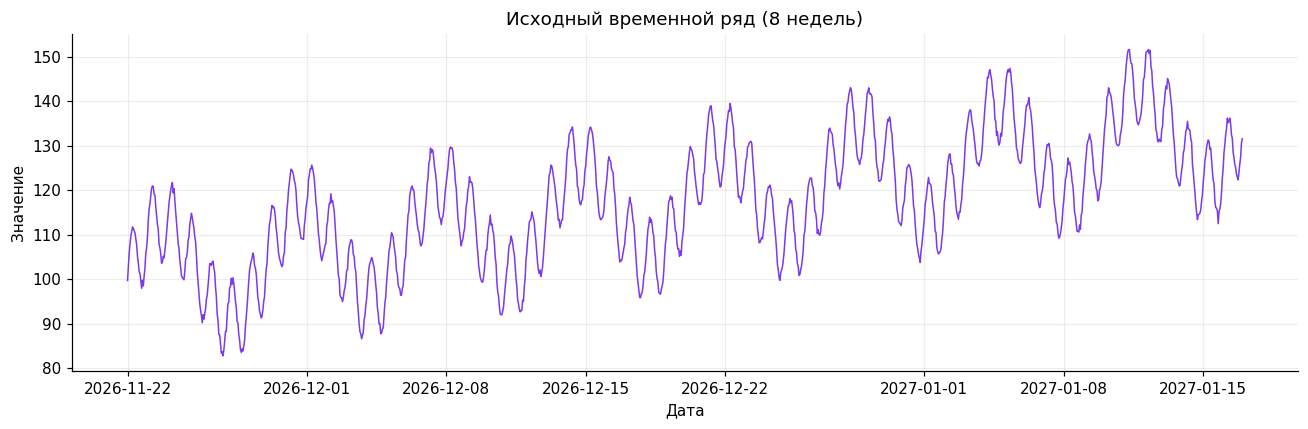

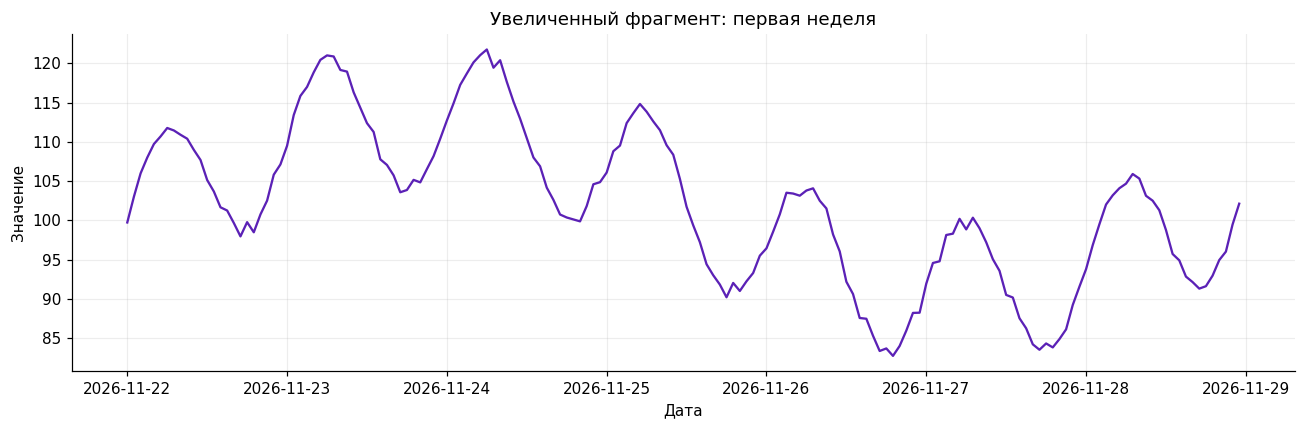

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, series, color=PURPLE, linewidth=1)
ax.set(title="Исходный временной ряд (8 недель)", xlabel="Дата", ylabel="Значение")
save_image("lab_image_1.png")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index[:168], series.iloc[:168], color=DARK, linewidth=1.5)
ax.set(title="Увеличенный фрагмент: первая неделя", xlabel="Дата", ylabel="Значение")
save_image("lab_image_2.png")

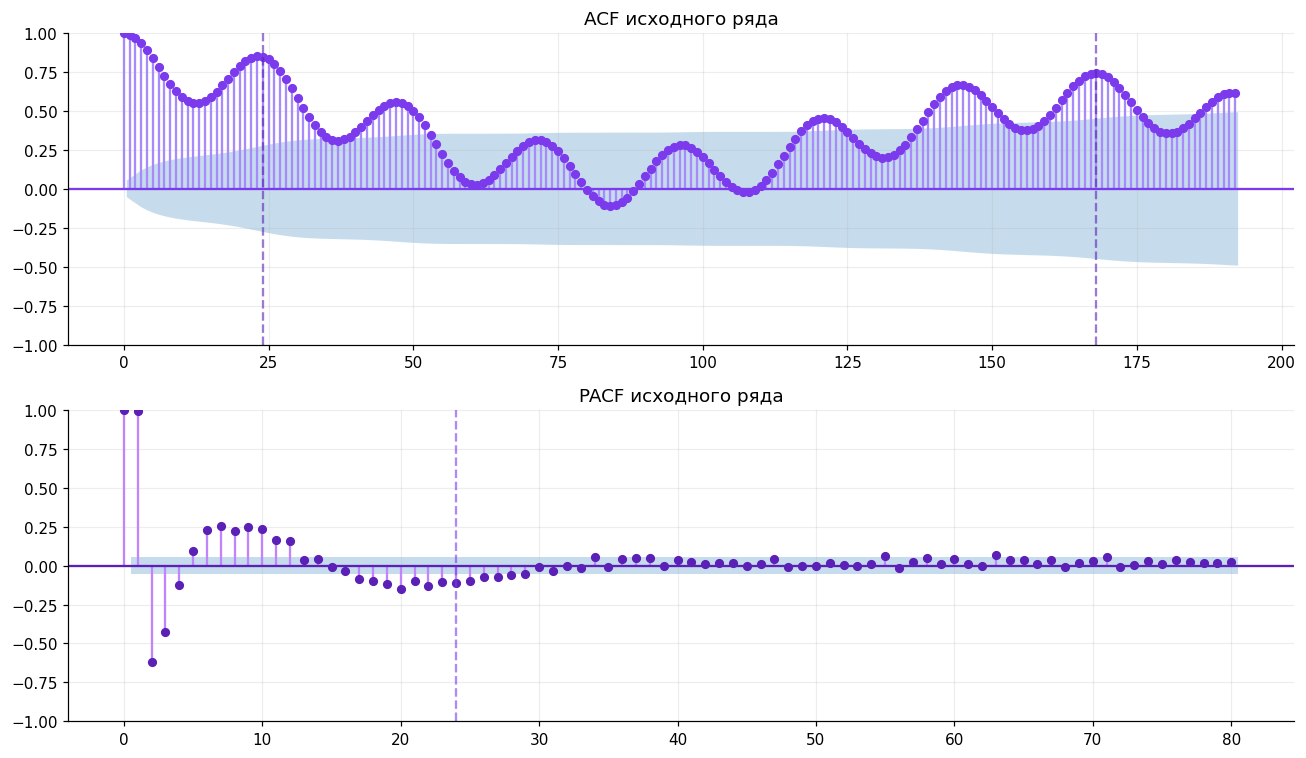

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(series, lags=192, ax=axes[0], color=PURPLE, vlines_kwargs={"colors": LILAC})
plot_pacf(series, lags=80, ax=axes[1], method="ywm", color=DARK, vlines_kwargs={"colors": PINK})
for x in (24, 168):
    axes[0].axvline(x, color=DARK, linestyle="--", alpha=0.6)
axes[1].axvline(24, color=PURPLE, linestyle="--", alpha=0.6)
axes[0].set_title("ACF исходного ряда")
axes[1].set_title("PACF исходного ряда")
save_image("lab_image_3.png")

## 5. Тесты стационарности: ADF, PP, KPSS, DF-GLS
***Нулевая гипотеза*** - это предположение, которое проверяется тестом
| Тест | Нулевая гипотеза $H_0$ | Интерпретация при $p < 0.05$ |
|---|---|---|
| ADF | Есть единичный корень | Отклоняем гипотезу о единичном корне |
| PP | Есть единичный корень | Отклоняем гипотезу о единичном корне |
| DF-GLS | Есть единичный корень | Отклоняем гипотезу о единичном корне |
| KPSS | Стационарность относительно уровня | Отклоняем гипотезу о стационарности |

Используется `regression="c"` (стационарность относительно постоянного уровня), чтобы последовательные преобразования сравнивались на единых условиях. Наличие детерминированного тренда может влиять на результаты - это отражено в интерпретации

In [10]:
"""Возвращает p-values четырёх тестов для одного ряда"""
def report_tests(x, name):
    clean = pd.Series(x).dropna().astype(float)

    adf_p = adfuller(
    clean,
    regression="c",
    autolag="AIC",
    result_object=False
)[1]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # KPSS иногда сообщает, что p вне диапазона таблицы
        kpss_p = kpss(clean, regression="c", nlags="auto")[1]

    # Эти две процедуры предоставляются библиотекой arch
    pp_p = PhillipsPerron(clean, trend="c").pvalue if ARCH_AVAILABLE else np.nan
    dfgls_p = DFGLS(clean, trend="c").pvalue if ARCH_AVAILABLE else np.nan

    return {
        "Ряд": name,
        "ADF p": adf_p,
        "PP p": pp_p,
        "KPSS p": kpss_p,
        "DF-GLS p": dfgls_p,
    }

results = [report_tests(series, "Исходный")]
print(pd.DataFrame(results).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
if not ARCH_AVAILABLE:
    print("Для полной таблицы установите arch и выполните все ячейки заново")

     Ряд  ADF p   PP p  KPSS p  DF-GLS p
Исходный 0.0000 0.2187  0.0100    0.0003


## 6. Первые разности и их влияние на стационарность
Первые разности рассчитываются по формуле:

$$\Delta Y_t = Y_t - Y_{t-1}$$

Они показывают **изменение относительно предыдущего часа**, а не исходный уровень. Постоянный линейный тренд превращается примерно в постоянную добавку. Сезонные колебания могут оставаться и после обычного дифференцирования, поэтому дополнительно проверяем ACF и тесты

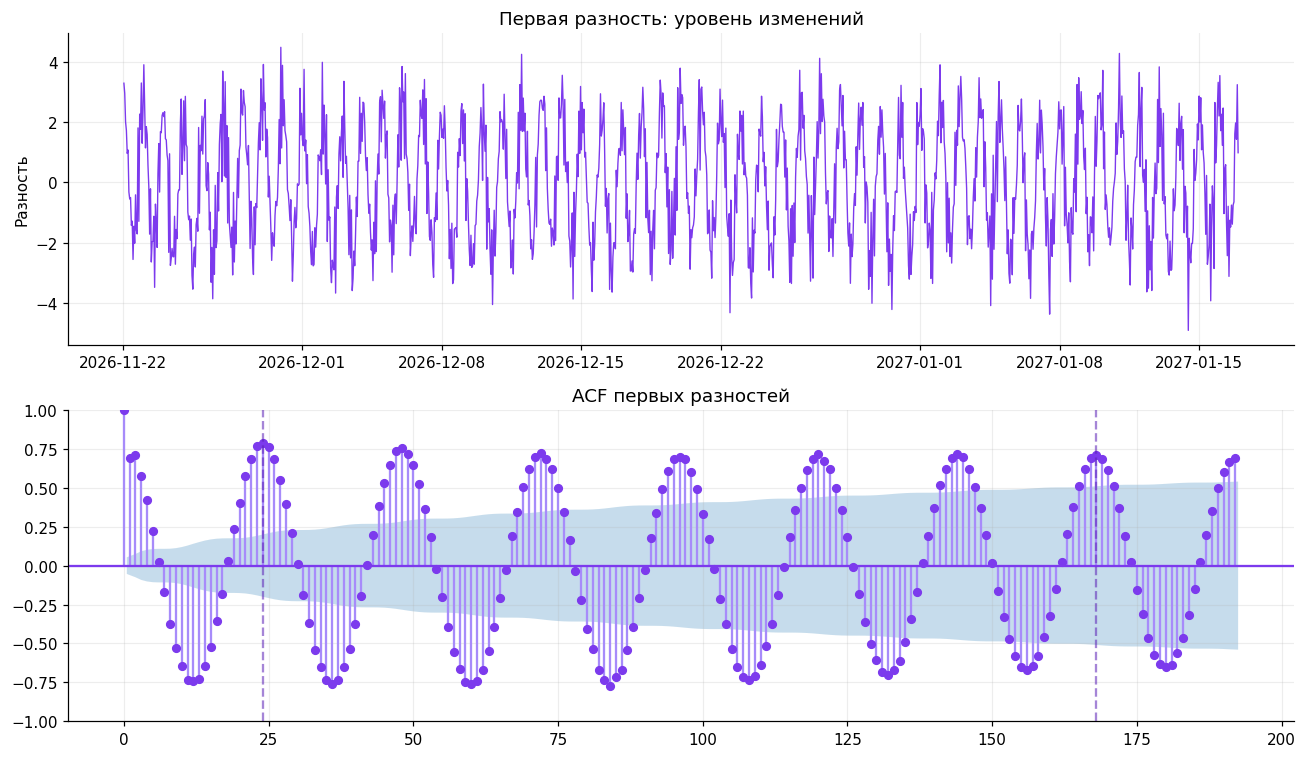

                  Ряд  ADF p   PP p  KPSS p  DF-GLS p
             Исходный 0.0000 0.2187  0.0100    0.0003
Первая разность (d=1) 0.1477 0.0000  0.1000    0.6136


In [11]:
diff1 = series.diff().dropna()
results.append(report_tests(diff1, "Первая разность (d=1)"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(diff1.index, diff1, color=PURPLE, linewidth=0.9)
axes[0].set(title="Первая разность: уровень изменений", ylabel="Разность")
plot_acf(diff1, lags=192, ax=axes[1], color=PURPLE, vlines_kwargs={"colors": LILAC})
for x in (24, 168):
    axes[1].axvline(x, color=DARK, linestyle="--", alpha=0.55)
axes[1].set_title("ACF первых разностей")
save_image("lab_image_4.png")
print(pd.DataFrame(results).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

## 7. Сезонные разности
Сезонная разность для периода $s$:

$$\Delta_s Y_t = Y_t - Y_{t-s}$$

В нашем примере $s=24$ соответствует одним суткам. Последовательно проверим:
- одну сезонную разность на исходном ряду: $\Delta_{24}Y_t$
- сочетание обычной и суточной сезонной разности: $\Delta_{24}\Delta Y_t$
- дополнительную недельную разность (168 часов) **только для демонстрации**, потому что в данных есть и недельный цикл

**Важно:** сезонная разность с периодом 168 сама по себе уже убирает повторяющиеся компоненты периодов 168 и 24, поскольку 168 кратно 24. Поэтому одновременно применять обе сезонные разности обычно избыточно. Мы сравниваем варианты, но выбераем минимально достаточное преобразование

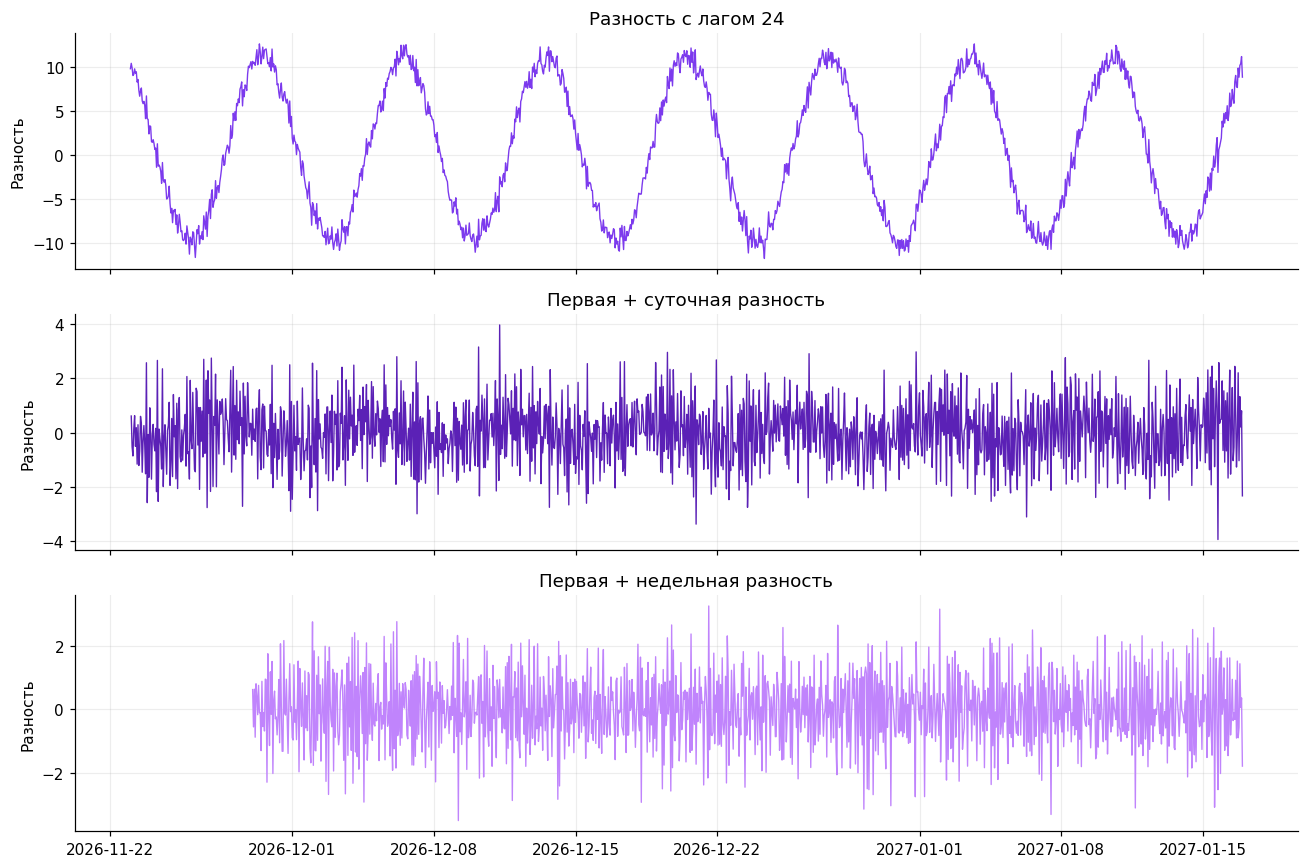

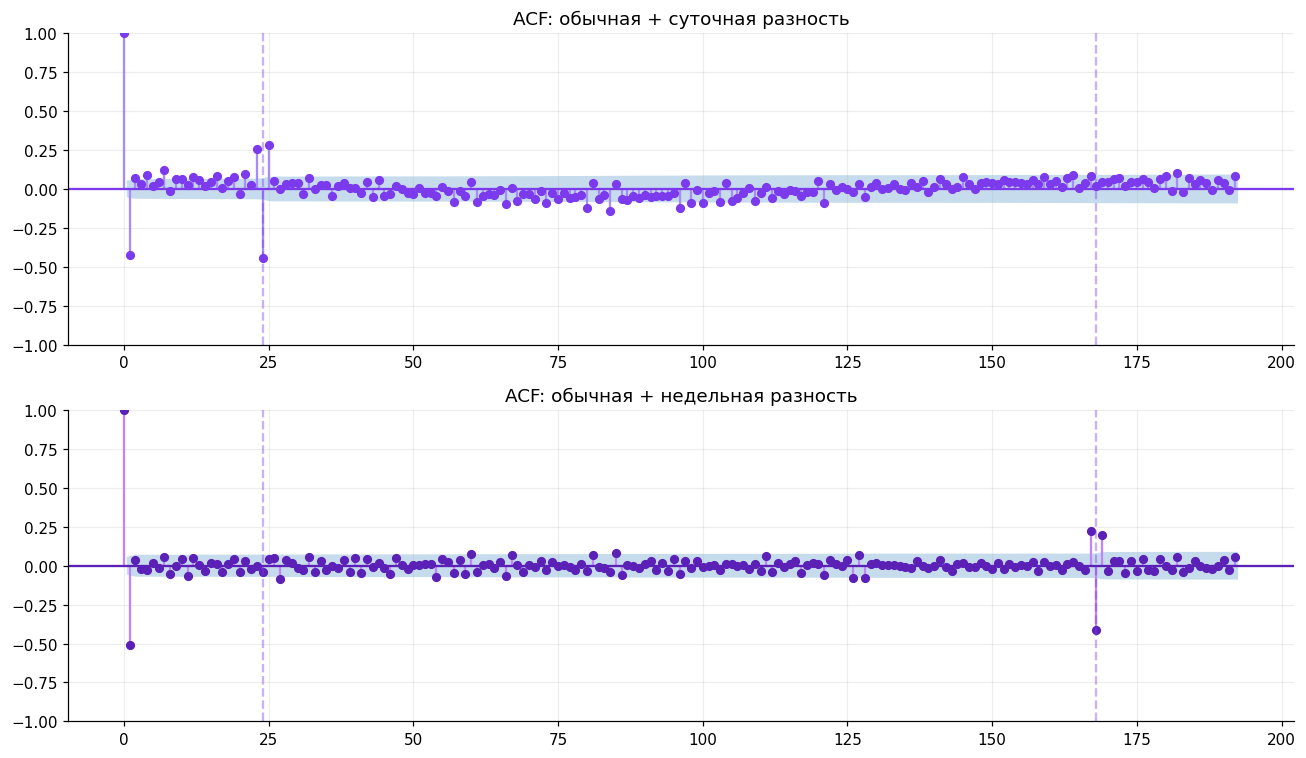

In [12]:
seasonal_24 = series.diff(24).dropna()
diff1_seasonal_24 = diff1.diff(24).dropna()
diff1_seasonal_168 = diff1.diff(168).dropna()

results.append(report_tests(seasonal_24, "Сезонная разность (D24=1)"))
results.append(report_tests(diff1_seasonal_24, "Первая + суточная"))
results.append(report_tests(diff1_seasonal_168, "Первая + недельная"))

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (title, values, color) in zip(axes, [
    ("Разность с лагом 24", seasonal_24, PURPLE),
    ("Первая + суточная разность", diff1_seasonal_24, DARK),
    ("Первая + недельная разность", diff1_seasonal_168, PINK),
]):
    ax.plot(values.index, values, color=color, linewidth=0.9)
    ax.set_ylabel("Разность")
    ax.set_title(title)
save_image("lab_image_5.png")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(diff1_seasonal_24, lags=192, ax=axes[0], color=PURPLE, vlines_kwargs={"colors": LILAC})
plot_acf(diff1_seasonal_168, lags=192, ax=axes[1], color=DARK, vlines_kwargs={"colors": PINK})
axes[0].set_title("ACF: обычная + суточная разность")
axes[1].set_title("ACF: обычная + недельная разность")
for ax in axes:
    for x in (24, 168):
        ax.axvline(x, color=PURPLE, linestyle="--", alpha=0.4)
save_image("lab_image_6.png")

## 8. Таблица p-values и согласованная интерпретация
**Порог значимости**: $\alpha=0.05$. Уровень $p$ - не вероятность истинности гипотезы. Поскольку KPSS имеет противоположную нулевую гипотезу, будем использовать два простых правила:
- ADF $p<0.05$ и KPSS $p\geq0.05$: тесты согласуются в пользу стационарности относительно уровня
- ADF $p\geq0.05$ и KPSS $p<0.05$: тесты согласуются в пользу нестационарности
- другие комбинации: неоднозначный результат, необходимо анализировать графики, сезонность и дополнительные тесты

Для PP и DF-GLS также смотрим, отвергается ли гипотеза о единичном корне. KPSS в `statsmodels` ограничивает табличный диапазон `p-values`, значения у краёв нужно интерпретировать осторожно

In [13]:
table = pd.DataFrame(results).set_index("Ряд")

def interpretation(row):
    stationary_adf = row["ADF p"] < 0.05
    stationary_kpss = row["KPSS p"] >= 0.05
    if stationary_adf and stationary_kpss:
        return "Тесты согласуются: в пользу стационарности"
    if not stationary_adf and not stationary_kpss:
        return "Тесты согласуются: в пользу нестационарности"
    return "Противоречие тестов: нужна дополнительная проверка"

table["Интерпретация ADF + KPSS"] = table.apply(interpretation, axis=1)
table.to_csv("stationarity_tests.csv", float_format="%.6f")
print(table.to_string(float_format=lambda x: f"{x:.4f}"))

# Диагностика: ACF на целевых лагах (без лаг-0, который всегда равен 1)
acf_rows = []
for name, data in [
    ("Исходный", series), ("Первая разность", diff1),
    ("Первая + суточная", diff1_seasonal_24),
    ("Первая + недельная", diff1_seasonal_168),
]:
    coefficients = acf(data, nlags=168, fft=True)
    acf_rows.append({"Ряд": name, "ACF(24)": coefficients[24],
                     "ACF(168)": coefficients[168]})
acf_table = pd.DataFrame(acf_rows).set_index("Ряд")
acf_table.to_csv("acf_comparison.csv", float_format="%.6f")
print("\nACF для ключевых лагов:")
print(acf_table.round(4).to_string())

                           ADF p   PP p  KPSS p  DF-GLS p                            Интерпретация ADF + KPSS
Ряд                                                                                                          
Исходный                  0.0000 0.2187  0.0100    0.0003  Противоречие тестов: нужна дополнительная проверка
Первая разность (d=1)     0.1477 0.0000  0.1000    0.6136  Противоречие тестов: нужна дополнительная проверка
Сезонная разность (D24=1) 0.0000 0.0076  0.1000    0.0000          Тесты согласуются: в пользу стационарности
Первая + суточная         0.0354 0.0000  0.1000    0.0944          Тесты согласуются: в пользу стационарности
Первая + недельная        0.0000 0.0000  0.1000    0.4915          Тесты согласуются: в пользу стационарности

ACF для ключевых лагов:
                    ACF(24)  ACF(168)
Ряд                                  
Исходный             0.8488    0.7445
Первая разность      0.7866    0.7103
Первая + суточная   -0.4430    0.0172
Первая + недель

## 9. Автоматический подбор порядка дифференцирования
Функция `ndiffs()` предлагает число обычных разностей $d$. Функция `nsdiffs()` - число сезонных разностей $D$ для заданного периода $m$

Рекомендуемые тесты могут приводить к разным решениям, значения $d$ и $D$ не нужно механически складывать или принимать без проверки. Для наших почасовых данных рассмотрим 24-часовой период и дополнительно 168-часовой период. Недельный вызов может быть более затратным по времени, поэтому для него используем метод OCSB и ограничение максимального числа разностей

In [14]:
# Рекомендации для обычного дифференцирования
d_kpss = ndiffs(series, test="kpss", max_d=2)
d_adf = ndiffs(series, test="adf", max_d=2)

# Поиск сезонных разностей для двух известных периодов
D_24 = nsdiffs(series, m=24, test="ocsb", max_D=1)
D_168 = nsdiffs(series, m=168, test="ocsb", max_D=1)

recommendations = pd.DataFrame([
    {"Параметр": "d (KPSS)", "Рекомендация": d_kpss},
    {"Параметр": "d (ADF)", "Рекомендация": d_adf},
    {"Параметр": "D (24 часа, OCSB)", "Рекомендация": D_24},
    {"Параметр": "D (168 часов, OCSB)", "Рекомендация": D_168},
])
print(recommendations.to_string(index=False))
recommendations.to_csv("d_recommendations.csv", index=False)

           Параметр  Рекомендация
           d (KPSS)             1
            d (ADF)             1
  D (24 часа, OCSB)             0
D (168 часов, OCSB)             0


## 10. Сравнение ручного и автоматического решений
Для демонстрации различных преобразований мы проверили комбинации $d=0,1$, $D=0,1$ для периодов 24 и 168 часов. Однако это не означает, что нужно обязательно использовать максимальное количество разностей

У синтетического ряда сезонности заданы детерминированными синусоидами, а не сезонными единичными корнями. Поэтому `nsdiffs()` может вполне обоснованно рекомендовать $D=0$, хотя на графике ACF видны сезонные пики. В этом случае для удаления сезонной компоненты можно использовать моделирование сезонности или STL/MSTL, а не обязательное сезонное дифференцирование

Также модель с детерминированным линейным трендом может быть стационарной относительно тренда, но не стационарной относительно постоянного уровня. В данном задании мы сравниваем тесты относительно уровня и прямо учитываем эту оговорку

Минимальное преобразование по согласованию ADF + KPSS: Сезонная 24
Ручная оценка: d=0, D=1, период=24


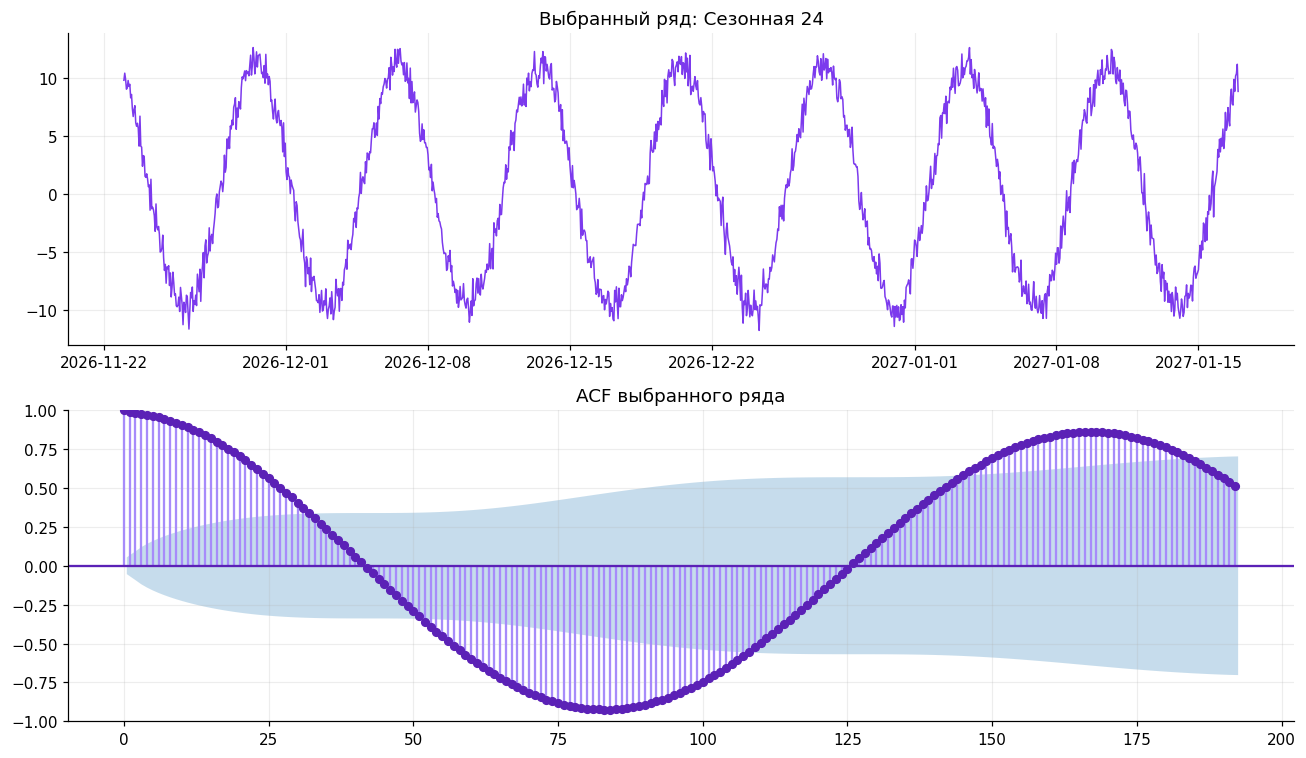

In [15]:
# Выбираем минимальный по сложности вариант из подготовленных рядов,
# который согласуется по ADF и KPSS относительно постоянного уровня
candidates = [
    ("Без разностей", series, 0, 0, None),
    ("Первая разность", diff1, 1, 0, None),
    ("Сезонная 24", seasonal_24, 0, 1, 24),
    ("Первая + сезонная 24", diff1_seasonal_24, 1, 1, 24),
    ("Первая + сезонная 168", diff1_seasonal_168, 1, 1, 168),
]

passing = []
for label, data, d, D, m in candidates:
    vals = report_tests(data, label)
    if vals["ADF p"] < 0.05 and vals["KPSS p"] >= 0.05:
        passing.append((d + D, d, D, label, data, m))

if passing:
    _, selected_d, selected_D, selected_name, final_series, selected_period = min(
        passing, key=lambda item: (item[0], item[1], item[2])
    )
    print("Минимальное преобразование по согласованию ADF + KPSS:", selected_name)
    print(f"Ручная оценка: d={selected_d}, D={selected_D}, период={selected_period}")
else:
    # Не выдаём неоднозначную проверку за подтверждённую стационарность
    selected_name = "Первая + сезонная 168 (для дальнейшей диагностики)"
    final_series = diff1_seasonal_168
    selected_d, selected_D, selected_period = 1, 1, 168
    print("Тесты не дали однозначной стационарности ни для одного варианта")
    print("Показываем вариант с недельной разностью для дальнейшей диагностики")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(final_series.index, final_series, color=PURPLE, linewidth=1)
axes[0].set_title("Выбранный ряд: " + selected_name)
plot_acf(final_series, lags=192, ax=axes[1], color=DARK,
         vlines_kwargs={"colors": LILAC})
axes[1].set_title("ACF выбранного ряда")
save_image("lab_image_7.png")

## Итоговый вывод

В ходе лабораторной работы был проведён анализ стационарности синтетического временного ряда, созданного с помощью генератора из лабораторной работы № 1

На основании проведённого исследования можно сделать следующие выводы:

1. **Анализ исходного ряда.** Временной ряд содержит тренд и сезонные колебания. Графики `ACF` и `PACF` позволили исследовать зависимости между наблюдениями при различных временных сдвигах

2. **Проверка стационарности.** Для исходного ряда были применены тесты `ADF`, `PP`, `KPSS` и `DF-GLS`. Полученные результаты оказались противоречивыми: `ADF` и `DF-GLS` отвергли гипотезу о наличии единичного корня, `PP` не отверг её, а `KPSS` отверг гипотезу о стационарности. Следовательно, результаты не позволяют однозначно считать исходный ряд стационарным

3. **Преобразование временного ряда.** Для устранения тренда и сезонных колебаний были рассмотрены первые и сезонные разности. После преобразований повторно исследовались графики и результаты статистических тестов

4. **Сравнение преобразований.** Среди проверенных вариантов сезонное дифференцирование с периодом 24 часа показало согласованные результаты тестов `ADF` и `KPSS`: `ADF` отверг гипотезу о единичном корне, а `KPSS` не отверг гипотезу о стационарности. Это указывает на целесообразность данного преобразования для исследуемого ряда

5. **Автоматический подбор параметров.** Для определения порядка обычного и сезонного дифференцирования использовались функции `ndiffs()` и `nsdiffs()`. Их рекомендации сравнивались с результатами ручного анализа. Различия между рекомендациями показывают, что автоматический подбор необходимо дополнять исследованием графиков и статистическими тестами

**Общий вывод:** в ходе лабораторной работы были изучены методы проверки стационарности временных рядов и способы их преобразования. Установлено, что для исследуемых данных сезонное дифференцирование с периодом 24 часа является подходящим вариантом по результатам `ADF` и `KPSS`. При этом окончательную оценку стационарности необходимо проводить с учётом всех применённых тестов и анализа автокорреляции

Таким образом, цель лабораторной работы достигнута: выполнены корреляционный анализ, проверка стационарности, сравнение способов дифференцирования и подбор параметров преобразования временного ряда